# Case Study 21 — Does Cashback Reduce Churn?

**Association vs causation · confounding and selection into treatment · reverse causality · mediators and "bad controls" ·
adjustment ladders and propensity weighting · what a randomised pilot adds · intention-to-treat and complier effects ·
sensitivity (E-values) · precise causal language**

| | |
|---|---|
| **Domain** | Credit cards: customer retention |
| **Stakeholders** | Head of Cards Marketing, Retention, Finance |
| **Difficulty** | Intermediate to advanced |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 04 (randomised tests), Case 08 (confounding), Case 11 (logistic regression), Case 20 (Simpson's paradox) |
| **Data** | 20,000 customers who chose whether to enrol (observational); a randomised pilot of 16,000 customers |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A teaching-only answer key (each customer's churn probability with and without
> cashback) is opened only in Section 11. Sections 4 to 10 use only information a real analyst would have.

**What you will learn**

1. Why "enrolled customers churn far less" is not "cashback reduces churn", and how to describe the gap in precise language.
2. How adjusting for observed variables changes the estimate, and why it still cannot be trusted when something unobserved drives both choices.
3. Which variables to control for (pre-treatment confounders) and which to leave out (mediators, consequences of the treatment).
4. What a randomised pilot adds, and how to read its intention-to-treat and complier estimates.
5. How strong a hidden confounder would have to be to explain an observed association (E-value).

## Section 1 — Business context

A card issuer lets customers opt into a cashback programme. Marketing reports:

> *"Customers enrolled in cashback churn at 7% a year against 26% for everyone else. Cashback cuts churn by two thirds.
> Let's move budget from retention calls into cashback and push enrolment to the whole base."*

The retention head is doubtful: *"The people who sign up are our most engaged customers anyway."* Last quarter a small
randomised pilot was run: a random half of 16,000 customers were offered cashback, the other half could not enrol.

## Section 2 — Business questions

1. What does the data say about churn for enrolled vs non-enrolled customers?
2. How much of that gap could be caused by who chooses to enrol?
3. What does adjusting for what we observe give, and can we trust it?
4. What does the randomised pilot say, and how do we read it when only some offered customers enrol?
5. How much should the budget move?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Gap in churn | Difference in churn rates, with CI | Two-proportion comparison |
| 2 | Who enrols? | Are enrolled and non-enrolled comparable before treatment? | Balance table, standardised differences |
| 3 | Adjusted gap | Effect of enrolment given observed covariates | Logistic regression ladder, propensity weighting; bad controls |
| 4 | Pilot | Effect of the *offer* (ITT) and of *enrolling* (complier effect) | Difference in means, Wald/IV estimator, bootstrap |
| 5 | Budget | Net value given the best estimate | Break-even analysis |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "21_cashback_churn_causality"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(2121)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

## Section 4 — Load the data

In [2]:
obs = pd.read_csv(PATHS["data"] / "observational_customers.csv")
pil = pd.read_csv(PATHS["data"] / "pilot_experiment.csv")
print(f"Observational: {len(obs):,} customers, {obs['enrolled'].mean():.1%} enrolled; missing {obs.isna().sum().sum()};  Pilot: {len(pil):,} customers, {pil['offered'].mean():.0%} offered; missing {pil.isna().sum().sum()}")
display(obs.head())
display(pil.head())

Observational: 20,000 customers, 51.9% enrolled; missing 0;  Pilot: 16,000 customers, 50% offered; missing 0


,customer_id,tenure_months,income_band,digital_logins_per_month,spend_3m_before,spend_trend_before,complaints_12m,enrolled,spend_3m_after,churned_12m
0,CB21100000,77,3,5,12.8000,10.1000,0,0,14.1000,0
1,CB21100001,68,2,6,3.3000,-27.2000,0,0,2.6000,1
2,CB21100002,24,3,5,12.0000,4.0000,1,0,11.0000,0
3,CB21100003,35,2,8,50.0000,18.3000,0,1,69.3000,0
4,CB21100004,51,3,7,18.6000,6.0000,1,0,18.5000,0


,customer_id,tenure_months,income_band,digital_logins_per_month,spend_3m_before,spend_trend_before,complaints_12m,offered,enrolled,churned_12m
0,CB21P100000,36,1,2,4.2000,-20.5000,0,0,0,0
1,CB21P100001,66,2,6,8.0000,-3.3000,0,1,1,0
2,CB21P100002,39,2,5,15.4000,-14.0000,0,1,1,0
3,CB21P100003,105,2,1,7.6000,-12.1000,0,0,0,0
4,CB21P100004,15,4,2,9.2000,0.2000,0,0,0,0


## Section 5 — The headline: enrolled customers churn far less

In [3]:
g = obs.groupby("enrolled")["churned_12m"].agg(["sum", "size"])
g["churn rate"] = g["sum"] / g["size"]
g[["ci_low", "ci_high"]] = [wilson(k, n) for k, n in zip(g["sum"], g["size"])]
r1, r0 = g.loc[1, "churn rate"], g.loc[0, "churn rate"]
se = np.sqrt(r1 * (1 - r1) / g.loc[1, "size"] + r0 * (1 - r0) / g.loc[0, "size"])
naive = {"difference (pp)": 100 * (r1 - r0), "ci_low": 100 * (r1 - r0 - 1.96 * se), "ci_high": 100 * (r1 - r0 + 1.96 * se), "relative reduction": 1 - r1 / r0}
naive_tbl = pd.DataFrame(naive, index=["enrolled minus not enrolled"])
save_table(g, "churn_by_enrolment", PATHS["tables"]); save_table(naive_tbl, "naive_difference", PATHS["tables"])
display(g)
display(naive_tbl)

,sum,size,churn rate,ci_low,ci_high
enrolled,,,,,
0,2530,9614,0.2632,0.2545,0.2721
1,722,10386,0.0695,0.0648,0.0746


,difference (pp),ci_low,ci_high,relative reduction
enrolled minus not enrolled,-19.3641,-20.3711,-18.3571,0.7358


**Observation.** Enrolled customers churned at **7.0%** against **26.3%** for the rest: a gap of **−19.4 percentage points**
(95% CI −20.4 to −18.4), a 74% lower churn rate. With 20,000 customers the gap is precise.

**Interpretation.** This is an **association**: "customers who enrolled churned less". It does not say "cashback reduced churn
by 19 points". The interval measures sampling error only. Before reading the gap as an effect we must ask who chose to enrol.

## Section 6 — Who chooses to enrol? Selection into treatment

If enrolment were random, enrolled and non-enrolled customers would look alike **before** enrolling. We compare variables
measured before the decision, using the standardised mean difference (SMD; |SMD| above 0.1 is a conventional warning sign).

,enrolled mean,not enrolled mean,SMD
variable,,,
tenure_months,46.7951,34.1103,0.4811
income_band,2.6375,2.3582,0.3718
digital_logins_per_month,6.9725,4.4475,0.9439
spend_3m_before,19.4965,11.0438,0.9142
spend_trend_before,5.8702,-6.3220,1.1881
complaints_12m,0.1982,0.2484,-0.0966


Same check in the randomised pilot (offered vs not offered):


,offered mean,not offered mean,SMD
variable,,,
tenure_months,40.8681,40.5217,0.0127
income_band,2.4934,2.5004,-0.0092
digital_logins_per_month,5.7124,5.7293,-0.0057
spend_3m_before,15.2326,15.2960,-0.0063
spend_trend_before,-0.0362,0.1294,-0.0137
complaints_12m,0.2240,0.2221,0.0036


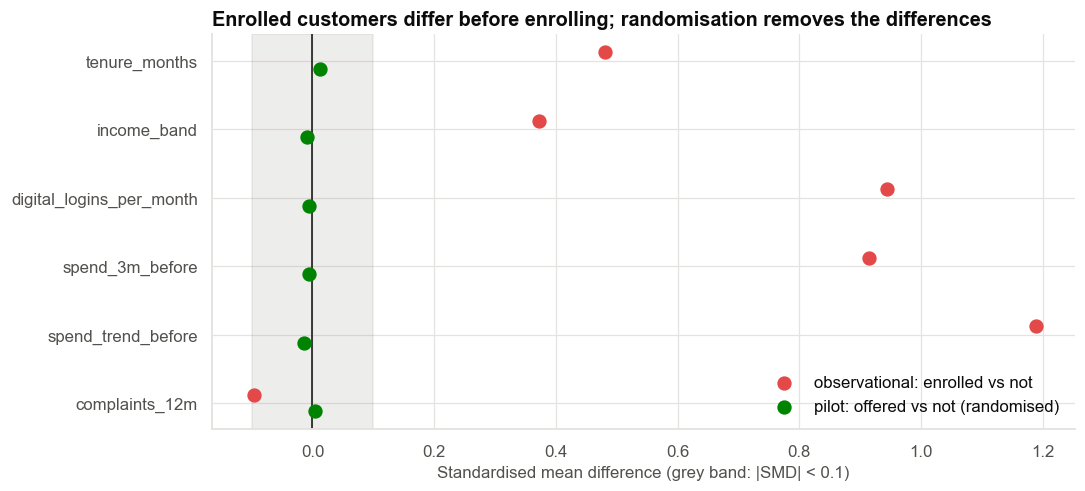

In [4]:
pre = ["tenure_months", "income_band", "digital_logins_per_month", "spend_3m_before", "spend_trend_before", "complaints_12m"]
rows = []
for c in pre:
    a, b = obs.loc[obs.enrolled == 1, c], obs.loc[obs.enrolled == 0, c]
    rows.append({"variable": c, "enrolled mean": a.mean(), "not enrolled mean": b.mean(), "SMD": (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)})
bal = pd.DataFrame(rows).set_index("variable")
save_table(bal, "balance_observational", PATHS["tables"])
display(bal)
rows = []
for c in pre:
    a, b = pil.loc[pil.offered == 1, c], pil.loc[pil.offered == 0, c]
    rows.append({"variable": c, "offered mean": a.mean(), "not offered mean": b.mean(), "SMD": (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)})
bal_p = pd.DataFrame(rows).set_index("variable")
save_table(bal_p, "balance_pilot", PATHS["tables"])
print("Same check in the randomised pilot (offered vs not offered):")
display(bal_p)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(pre))[::-1]
ax.scatter(bal["SMD"], y + 0.12, color=COLORS["red"], s=70, label="observational: enrolled vs not", zorder=3)
ax.scatter(bal_p["SMD"], y - 0.12, color=COLORS["green"], s=70, label="pilot: offered vs not (randomised)", zorder=3)
ax.axvline(0, color=INK, lw=1); ax.axvspan(-0.1, 0.1, color=INK_MUTED, alpha=0.15)
ax.set_yticks(y, pre); ax.set(xlabel="Standardised mean difference (grey band: |SMD| < 0.1)", title="Enrolled customers differ before enrolling; randomisation removes the differences")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save_fig(fig, "fig01_balance", PATHS["figures"]); plt.show()

**Observation.** Enrolled customers differ sharply before they enrol: they have more tenure (SMD 0.48), more digital logins (0.94),
higher prior spend (0.91) and, most strikingly, a **rising spend trend** (SMD 1.19; +5.9% against −6.3%). In the randomised pilot every SMD is
below 0.015: the lottery made offered and not-offered customers alike.

**Interpretation.** Engaged customers opt in, and engaged customers churn less anyway. That is **confounding through selection into
treatment**. The spend-trend gap also hints at **reverse causality**: customers already drifting away stop spending and do not enrol.

## Section 7 — Method selection

Three families of answer, and what each can and cannot do.

| Approach | Idea | Removes | Cannot remove |
|---|---|---|---|
| **Adjust** (regression) | Compare enrolled and not at the same values of observed pre-treatment variables | Confounding by what we measured | Confounding by what we did not (engagement, intention to leave) |
| **Weight** (propensity score) | Reweight non-enrolled customers to look like the enrolled on observed variables | Same as above, with fewer modelling assumptions | Same |
| **Randomise** | An offer assigned by lottery | Confounding by anything, measured or not | Non-compliance: some offered customers do not enrol |

**Which variables to include.** Include variables that **precede** enrolment and affect both enrolment and churn
(**confounders**). Do not include variables that are **caused by** enrolment (**mediators**, such as spend after enrolment);
controlling for them removes part of the effect we want to measure. Variables that merely **result from** the outcome
or from a decision to leave (a falling spend trend just before the decision, in a world where leavers stop spending) are
**reverse-causality** traps, and their status needs thought, not mechanical inclusion.

## Section 8 — Adjustment ladder

We fit logistic regressions with more and more controls. The target is the average effect of enrolment among those who
enrolled, in percentage points of churn probability (predict churn for each enrolled customer with and without enrolment).

In [5]:
specs = {
    "1. none": "churned_12m ~ enrolled",
    "2. + tenure, income, complaints": "churned_12m ~ enrolled + tenure_months + C(income_band) + complaints_12m",
    "3. + spend, digital logins": "churned_12m ~ enrolled + tenure_months + C(income_band) + complaints_12m + np.log(spend_3m_before) + digital_logins_per_month",
    "4. + spend trend before decision": "churned_12m ~ enrolled + tenure_months + C(income_band) + complaints_12m + np.log(spend_3m_before) + digital_logins_per_month + spend_trend_before",
    "5. + spend AFTER enrolment (bad control)": "churned_12m ~ enrolled + tenure_months + C(income_band) + complaints_12m + np.log(spend_3m_before) + digital_logins_per_month + spend_trend_before + np.log(spend_3m_after)",
}
def att_pp(model, d):
    e = d[d.enrolled == 1]
    return 100 * (model.predict(e.assign(enrolled=1)) - model.predict(e.assign(enrolled=0))).mean()

B = 150
rows = []
for name, f in specs.items():
    m = smf.logit(f, obs).fit(disp=0)
    est = att_pp(m, obs)
    bs = []
    for _ in range(B):
        d = obs.iloc[rng.integers(0, len(obs), len(obs))]
        bs.append(att_pp(smf.logit(f, d).fit(disp=0), d))
    rows.append({"model": name, "log-odds of enrolment": m.params["enrolled"], "odds ratio": np.exp(m.params["enrolled"]),
                 "effect among enrolled (pp)": est, "ci_low": np.percentile(bs, 2.5), "ci_high": np.percentile(bs, 97.5)})
ladder = pd.DataFrame(rows).set_index("model")
save_table(ladder, "adjustment_ladder", PATHS["tables"])
display(ladder)

,log-odds of enrolment,odds ratio,effect among enrolled (pp),ci_low,ci_high
model,,,,,
1. none,-1.5645,0.2092,-19.3641,-20.4451,-18.5040
"2. + tenure, income, complaints",-1.4040,0.2456,-16.0820,-17.0031,-15.0641
"3. + spend, digital logins",-0.9979,0.3686,-9.5677,-10.5708,-8.4840
4. + spend trend before decision,-0.8006,0.4491,-7.0046,-8.1670,-6.1109
5. + spend AFTER enrolment (bad control),-0.8257,0.4379,-7.2942,-8.4253,-6.4615


**Observation.** As observed controls are added, the estimated effect among enrolled customers shrinks from **−19.4** to **−16.1**
(tenure, income, complaints), **−9.6** (spend and logins) and **−7.0 points** (spend trend before the decision), in each case with a narrow CI
that would be read as "precise". Adding spend *after* enrolment (a mediator) moves the estimate to −7.3 for the wrong reason.

**Interpretation.** Most of the naive gap is selection, and each reasonable control removes more of it. But the narrow intervals are misleading:
they describe sampling noise around an estimate that is still biased by what we cannot see (the latent engagement and intention to leave).
Without the answer key we would not know where the ladder stops.

### 8.1 Propensity-score weighting

The propensity score is the probability of enrolling given observed pre-treatment variables. Weighting non-enrolled customers by
p ÷ (1 − p) makes them resemble the enrolled on those variables (the "average effect on the enrolled"). We use the same variables as model 4, and check overlap and balance.

,estimate (pp),ci_low,ci_high,weighted control churn,enrolled churn,effective n of controls
propensity weighting (ATT),-6.2131,-7.6348,-4.5602,0.1316,0.0695,761.5192


,SMD before,SMD after weighting
variable,,
tenure_months,0.4811,0.0362
income_band,0.3718,0.0016
digital_logins_per_month,0.9439,0.0028
spend_3m_before,0.9142,0.0304
spend_trend_before,1.1881,0.0142
complaints_12m,-0.0966,0.0185


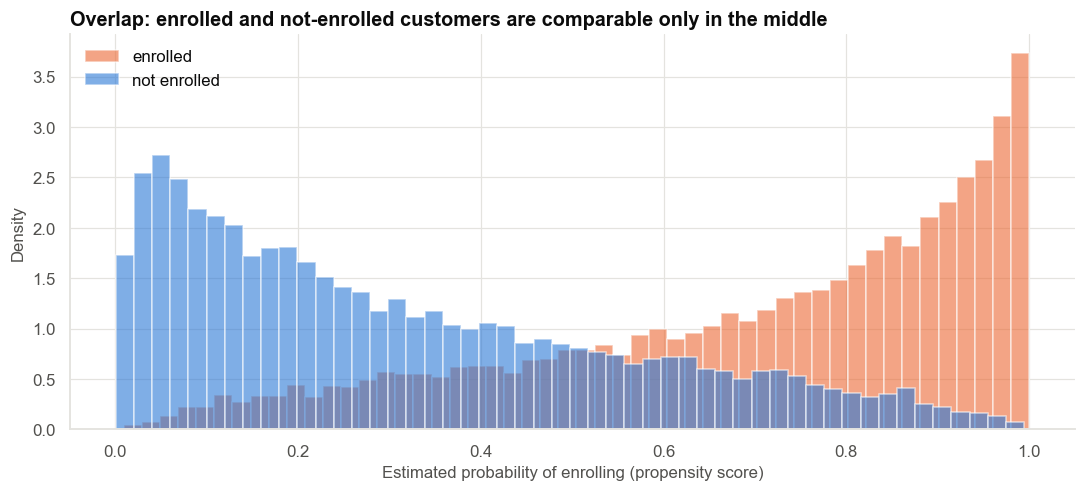

In [6]:
ps_f = "enrolled ~ tenure_months + C(income_band) + complaints_12m + np.log(spend_3m_before) + digital_logins_per_month + spend_trend_before"
ps_m = smf.logit(ps_f, obs).fit(disp=0)
obs["ps"] = ps_m.predict(obs)
w = np.where(obs.enrolled == 1, 1.0, obs.ps / (1 - obs.ps))
t = obs.enrolled == 1
churn_t = obs.loc[t, "churned_12m"].mean()
churn_c = np.average(obs.loc[~t, "churned_12m"], weights=w[~t])
def ipw_att(d):
    m = smf.logit(ps_f, d).fit(disp=0); p_ = m.predict(d); t_ = d.enrolled == 1; w_ = np.where(t_, 1.0, p_ / (1 - p_))
    return 100 * (d.loc[t_, "churned_12m"].mean() - np.average(d.loc[~t_, "churned_12m"], weights=w_[~t_]))
bs = [ipw_att(obs.iloc[rng.integers(0, len(obs), len(obs))]) for _ in range(150)]
ipw = pd.DataFrame({"estimate (pp)": [100 * (churn_t - churn_c)], "ci_low": [np.percentile(bs, 2.5)], "ci_high": [np.percentile(bs, 97.5)],
                    "weighted control churn": [churn_c], "enrolled churn": [churn_t], "effective n of controls": [w[~t].sum() ** 2 / (w[~t] ** 2).sum()]}, index=["propensity weighting (ATT)"])
save_table(ipw, "propensity_weighting", PATHS["tables"])
display(ipw)
bal_w = []
for c in pre:
    a = obs.loc[t, c]; b = obs.loc[~t, c]
    sd = np.sqrt((a.var() + b.var()) / 2)
    bal_w.append({"variable": c, "SMD before": (a.mean() - b.mean()) / sd, "SMD after weighting": (a.mean() - np.average(b, weights=w[~t])) / sd})
bal_w = pd.DataFrame(bal_w).set_index("variable")
display(bal_w)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.hist(obs.loc[t, "ps"], bins=50, alpha=0.6, color=COLORS["orange"], density=True, label="enrolled")
ax.hist(obs.loc[~t, "ps"], bins=50, alpha=0.6, color=PRIMARY, density=True, label="not enrolled")
ax.set(xlabel="Estimated probability of enrolling (propensity score)", ylabel="Density", title="Overlap: enrolled and not-enrolled customers are comparable only in the middle"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig02_propensity_overlap", PATHS["figures"]); plt.show()

**Observation.** Propensity weighting gives **−6.2 points** (95% CI −7.6 to −4.6), close to the regression estimate (−7.0). After
weighting, the observed variables are balanced (the table shows SMDs near zero), but the weighted control group rests on an effective sample of
only about 760 non-enrolled customers, and the overlap plot shows few non-enrolled customers resembling the most likely enrollees.

**Interpretation.** Weighting balances the **measured** variables. It says nothing about the unmeasured ones, so agreement between two
adjustment methods is not evidence that the answer is right.

## Section 9 — What can still be wrong? Reverse causality and the bad control

Look at **spend trend before the decision**. Customers who are about to leave tend to cut spending first, and customers who plan
to stay do not. So a customer's falling spend predicts **both** not enrolling and churning: the "cause" (enrolment) is partly a consequence
of a latent intention to leave. This is reverse causality (the outcome's precursor drives the exposure).

In [7]:
tr = obs.assign(trend_band=pd.qcut(obs["spend_trend_before"], 5, labels=["1 falling fastest", "2", "3", "4", "5 rising fastest"]))
tt = tr.groupby("trend_band", observed=True).agg(customers=("enrolled", "size"), enrolment_rate=("enrolled", "mean"), churn_rate=("churned_12m", "mean"))
# churn within trend band, by enrolment
tt["churn if enrolled"] = tr[tr.enrolled == 1].groupby("trend_band", observed=True)["churned_12m"].mean()
tt["churn if not enrolled"] = tr[tr.enrolled == 0].groupby("trend_band", observed=True)["churned_12m"].mean()
save_table(tt, "trend_band_table", PATHS["tables"])
display(tt)

,customers,enrolment_rate,churn_rate,churn if enrolled,churn if not enrolled
trend_band,,,,,
1 falling fastest,4021,0.1537,0.3283,0.1408,0.3623
2,4024,0.3477,0.1953,0.0944,0.2491
3,3966,0.5267,0.1462,0.0828,0.2168
4,3996,0.6997,0.0966,0.0733,0.1508
5 rising fastest,3993,0.8725,0.0451,0.0359,0.1081


**Observation.** Across the five spend-trend bands the enrolment rate climbs from 15% (falling fastest) to 87% (rising fastest) and the churn
rate falls from 33% to 4.5%. Within every band enrolled customers churn less, but the gaps are very different: 22 points in the lowest band
(14.1% vs 36.2%) and about 7 in the highest (3.6% vs 10.8%).

**Interpretation.** Spend trend predicts both who enrols and who churns, so it must be controlled for (as in model 4), and it is a proxy for the intention to leave that
we cannot observe directly. Conditioning on a proxy helps but does not remove the problem.

**A bad control.** Spend *after* enrolment is partly **caused by** enrolment (cashback raises spend, which is one way it could reduce churn). Model 5 above
adds it and the estimate changes only slightly here, but conceptually it takes away part of the effect we are trying to measure, so it should not be used for the total effect.

## Section 10 — The randomised pilot

In the pilot, offers were assigned by lottery, so offered and not-offered customers are comparable on everything (the balance
table above). But only some offered customers enrol, and control customers cannot enrol. Two questions follow:

- **Intention-to-treat (ITT):** what does *offering* cashback do to churn, for the whole population offered? Valid by randomisation.
- **Effect of enrolling (complier effect):** because enrolment is only possible with an offer, the ITT effect divided by the take-up rate is the average effect of enrolling among those who enrol (Wald estimator; it needs the offer to affect churn only through enrolment).

A comparison of enrolled against not-enrolled *within the pilot* is **not** valid: it reintroduces self-selection.

In [8]:
a = pil.groupby("offered")["churned_12m"].agg(["sum", "size"]); a["churn"] = a["sum"] / a["size"]
itt = 100 * (a.loc[1, "churn"] - a.loc[0, "churn"])
se_itt = 100 * np.sqrt(a.loc[1, "churn"] * (1 - a.loc[1, "churn"]) / a.loc[1, "size"] + a.loc[0, "churn"] * (1 - a.loc[0, "churn"]) / a.loc[0, "size"])
take = pil.loc[pil.offered == 1, "enrolled"].mean()
def wald(d):
    return 100 * (d.loc[d.offered == 1, "churned_12m"].mean() - d.loc[d.offered == 0, "churned_12m"].mean()) / d.loc[d.offered == 1, "enrolled"].mean()
bs = [wald(pil.iloc[rng.integers(0, len(pil), len(pil))]) for _ in range(2000)]
z = itt / se_itt
within = pil.groupby("enrolled")["churned_12m"].mean()
res_p = pd.DataFrame({"estimate (pp)": [itt, wald(pil), 100 * (within[1] - within[0])],
                      "ci_low": [itt - 1.96 * se_itt, np.percentile(bs, 2.5), np.nan], "ci_high": [itt + 1.96 * se_itt, np.percentile(bs, 97.5), np.nan]},
                     index=["ITT: effect of the OFFER (whole offered group)", "Complier effect: effect of ENROLLING (ITT ÷ take-up)", "Invalid: enrolled vs not enrolled inside the pilot"])
save_table(res_p, "pilot_results", PATHS["tables"])
print(f"Churn: offered {a.loc[1, 'churn']:.2%} vs not offered {a.loc[0, 'churn']:.2%}; take-up among offered {take:.1%}; ITT z = {z:.2f}, p = {fmt_p(2 * stats.norm.sf(abs(z)))}")
display(res_p)

Churn: offered 16.23% vs not offered 18.50%; take-up among offered 55.8%; ITT z = -3.80, p = < 0.001


,estimate (pp),ci_low,ci_high
ITT: effect of the OFFER (whole offered group),-2.2750,-3.4483,-1.1017
Complier effect: effect of ENROLLING (ITT ÷ take-up),-4.0798,-6.1338,-1.9998
Invalid: enrolled vs not enrolled inside the pilot,-13.6932,NaN,NaN


**Observation.** In the pilot, churn was **16.2%** among customers offered cashback and **18.5%** among those not offered: an **ITT effect of
−2.3 points** (95% CI −3.4 to −1.1). Only **55.8%** of those offered enrolled, so the effect of *enrolling* for those who enrol is
**−4.1 points** (95% CI −6.1 to −2.0). The invalid comparison of enrolled against not enrolled inside the pilot gives −13.7, almost
as misleading as the observational −19.4, because it again compares people who chose with people who did not.

**Interpretation.** The pilot gives two honest answers to two different questions: the offer reduces churn by about 2 points across everyone it
is offered to, and enrolling reduces churn by about 4 points for those who take it up. Neither is close to 19. The intervals are wider than the
observational ones, which is the price of an answer that does not depend on assumptions about hidden variables.

**Caveat.** The complier estimate needs the offer to act only through enrolment (the exclusion restriction), and it describes the customers who enrol
when offered, not necessarily the rest of the base.

## Section 11 — Grading against the truth (answer key)

The answer key holds each customer's churn probability with and without cashback. We can compute the true average effect among customers who enrolled.

TRUE average effect of cashback on churn: enrolled customers -4.33 pp; all customers -6.35 pp; pilot compliers -4.49 pp; true ITT of the offer -2.50 pp


,estimate (pp),ci_low,ci_high,truth it targets (pp),error (pp),CI covers the truth?
Naive difference,-19.3641,-20.3711,-18.3571,-4.3253,-15.0389,False
Adjusted 1. none,-19.3641,-20.4451,-18.5040,-4.3253,-15.0389,False
"Adjusted 2. + tenure, income, complaints",-16.0820,-17.0031,-15.0641,-4.3253,-11.7567,False
"Adjusted 3. + spend, digital logins",-9.5677,-10.5708,-8.4840,-4.3253,-5.2424,False
Adjusted 4. + spend trend before decision,-7.0046,-8.1670,-6.1109,-4.3253,-2.6793,False
Adjusted 5. + spend AFTER enrolment (bad control),-7.2942,-8.4253,-6.4615,-4.3253,-2.9690,False
Propensity weighting,-6.2131,-7.6348,-4.5602,-4.3253,-1.8878,False
Pilot ITT (effect of the offer),-2.2750,-3.4483,-1.1017,-2.5014,0.2264,True
Pilot complier effect (ITT ÷ take-up),-4.0798,-6.1338,-1.9998,-4.4859,0.4061,True


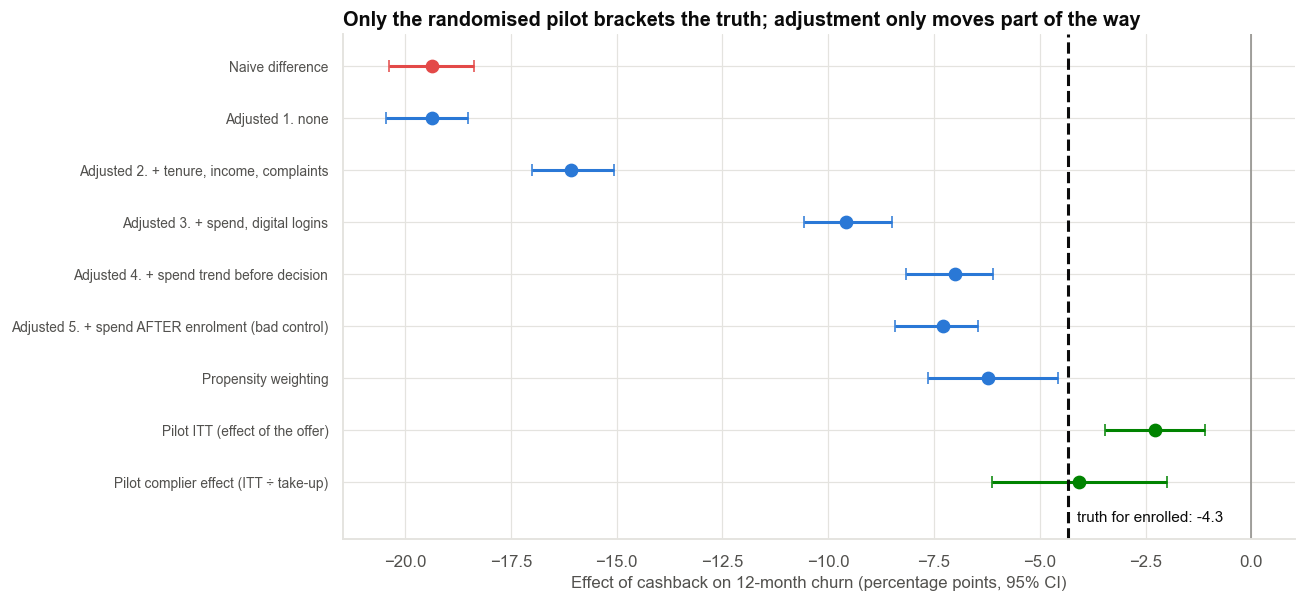

In [9]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv")
ko, kp = key.iloc[:len(obs)].reset_index(drop=True), key.iloc[len(obs):].reset_index(drop=True)
true_att = ko.loc[obs.enrolled == 1, "true_effect_pp"].mean()
true_all = ko["true_effect_pp"].mean()
true_comp = kp.loc[pil.enrolled == 1, "true_effect_pp"].mean()
true_itt = kp.loc[pil.enrolled == 1, "true_effect_pp"].sum() / (pil.offered == 1).sum()
grade = pd.DataFrame({
    "estimate (pp)": [naive["difference (pp)"]] + list(ladder["effect among enrolled (pp)"]) + [ipw.iloc[0, 0], itt, wald(pil)],
    "ci_low": [naive["ci_low"]] + list(ladder["ci_low"]) + [ipw.iloc[0, 1], itt - 1.96 * se_itt, np.percentile(bs, 2.5)],
    "ci_high": [naive["ci_high"]] + list(ladder["ci_high"]) + [ipw.iloc[0, 2], itt + 1.96 * se_itt, np.percentile(bs, 97.5)],
    "truth it targets (pp)": [true_att] * (1 + len(ladder) + 1) + [true_itt, true_comp],
}, index=["Naive difference"] + ["Adjusted " + i for i in ladder.index] + ["Propensity weighting", "Pilot ITT (effect of the offer)", "Pilot complier effect (ITT ÷ take-up)"])
grade["error (pp)"] = grade["estimate (pp)"] - grade["truth it targets (pp)"]
grade["CI covers the truth?"] = (grade["ci_low"] <= grade["truth it targets (pp)"]) & (grade["truth it targets (pp)"] <= grade["ci_high"])
save_table(grade, "grading", PATHS["tables"])
print(f"TRUE average effect of cashback on churn: enrolled customers {true_att:.2f} pp; all customers {true_all:.2f} pp; pilot compliers {true_comp:.2f} pp; true ITT of the offer {true_itt:.2f} pp")
display(grade)

fig, ax = plt.subplots(figsize=(12, 5.6))
rows_ = list(grade.index)[::-1]
for i, k_ in enumerate(rows_):
    r_ = grade.loc[k_]
    c = COLORS["red"] if k_.startswith("Naive") else (COLORS["green"] if k_.startswith("Pilot") else PRIMARY)
    ax.errorbar(r_["estimate (pp)"], i, xerr=[[r_["estimate (pp)"] - r_["ci_low"]], [r_["ci_high"] - r_["estimate (pp)"]]], fmt="o", color=c, capsize=4, ms=8, lw=2)
ax.axvline(true_att, color=INK, ls="--", lw=2); ax.text(true_att + 0.2, -0.75, f"truth for enrolled: {true_att:.1f}", fontsize=10); ax.set_ylim(-1.1, len(rows_) - 0.4)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set_yticks(range(len(rows_)), rows_, fontsize=9)
ax.set(xlabel="Effect of cashback on 12-month churn (percentage points, 95% CI)", title="Only the randomised pilot brackets the truth; adjustment only moves part of the way")
fig.tight_layout(); save_fig(fig, "fig03_estimates_vs_truth", PATHS["figures"]); plt.show()

**Observation.** The true average effect of cashback among enrolled customers is **−4.3 points** (−6.4 across all customers). The naive gap
overstates it **4.5 times** (−19.4). Each added control moves the adjusted estimate closer (−16.1, −9.6, −7.0) and propensity weighting
reaches −6.2, but **none of those intervals contains the truth**: they are narrow and wrong. The pilot's complier estimate (−4.1, CI −6.1 to −2.0)
contains it. The pilot's ITT is a different quantity (the effect of the offer, which is diluted by take-up); its true value is about −2.5.

**Interpretation.** Adjustment narrows the gap but gives false confidence. Randomisation gave the only interval that brackets the truth, and it did
so without our needing to know which variables to control for.

## Section 12 — How strong would a hidden confounder have to be? The E-value

Suppose a skeptic says the remaining association is entirely due to something unmeasured. The **E-value** for a risk ratio RR (below 1: use 1/RR) is
RR + √(RR(RR − 1)): the minimum strength of association (as a risk ratio) an unmeasured confounder would need with *both* enrolment and churn to explain the result away.

In [10]:
def evalue(rr):
    rr = 1 / rr if rr < 1 else rr
    return rr + np.sqrt(rr * (rr - 1))
m4 = smf.logit(specs["4. + spend trend before decision"], obs).fit(disp=0)
e = obs[obs.enrolled == 1]
p1 = m4.predict(e.assign(enrolled=1)).mean(); p0 = m4.predict(e.assign(enrolled=0)).mean()
rr_adj = p1 / p0; rr_naive = r1 / r0
# pilot: risk ratio of offer
rr_itt = a.loc[1, "churn"] / a.loc[0, "churn"]
ev = pd.DataFrame({"risk ratio (churn)": [rr_naive, rr_adj, rr_itt], "E-value": [evalue(rr_naive), evalue(rr_adj), evalue(rr_itt)]},
                  index=["Naive", "Adjusted (model 4)", "Pilot ITT"])
save_table(ev, "e_values", PATHS["tables"])
display(ev)

,risk ratio (churn),E-value
Naive,0.2642,7.0328
Adjusted (model 4),0.4981,3.4299
Pilot ITT,0.8770,1.5401


**Observation.** The naive risk ratio of 0.26 has an E-value of 7.0, the adjusted ratio (0.50) an E-value of 3.4. A hidden factor
associated with both enrolment and churn by a risk ratio of 3.4 would be enough to explain the whole adjusted result away; one of 7.0 for the naive result.

**Interpretation.** Is a factor that strongly associated with both plausible? Engagement and intention to leave plausibly are: spend trend alone has an SMD of 1.2 with enrolment.
The E-value does not tell us the answer, it tells us how much hidden bias the claim must survive, and here the answer is "not much".

## Section 13 — From effect to decision

In [11]:
BASE = 200_000            # customers who would be pushed into enrolment
CLV = 6_000               # margin lost per churner (Rs)
COST = 450                # annual cost of cashback per enrolled customer (Rs)
rows = []
for name, eff, cl, ch in [("Marketing's naive number", -naive["difference (pp)"], -naive["ci_low"], -naive["ci_high"]),
                          ("Pilot complier effect", -wald(pil), -np.percentile(bs, 2.5), -np.percentile(bs, 97.5)),
                          ("Truth (answer key)", -true_att, np.nan, np.nan)]:
    rows.append({"basis": name, "churn reduction (pp)": eff, "churners avoided per 1000 enrolled": 10 * eff,
                 "value per enrolled customer (Rs)": eff / 100 * CLV, "net per enrolled customer (Rs)": eff / 100 * CLV - COST})
econ = pd.DataFrame(rows).set_index("basis")
be = 100 * COST / CLV
save_table(econ, "decision_economics", PATHS["tables"])
print(f"Break-even churn reduction = Rs{COST} / Rs{CLV:,} = {be:.1f} pp per enrolled customer")
display(econ)

Break-even churn reduction = Rs450 / Rs6,000 = 7.5 pp per enrolled customer


,churn reduction (pp),churners avoided per 1000 enrolled,value per enrolled customer (Rs),net per enrolled customer (Rs)
basis,,,,
Marketing's naive number,19.3641,193.6412,"1,161.8474",711.8474
Pilot complier effect,4.0798,40.7980,244.7882,-205.2118
Truth (answer key),4.3253,43.2527,259.5160,-190.4840


**Observation.** Cashback costs about ₹450 a year per enrolled customer, and each churner costs about ₹6,000 in margin (assumptions for Finance to change).
The break-even is therefore a **7.5-point** reduction in churn. On Marketing's number (−19.4) the programme looks very profitable
(about +₹710 per customer). On the pilot's complier effect (−4.1) it **loses** about ₹205 per enrolled customer, and the truth (−4.3) says the same
(about −₹190). Even the average effect over all customers (−6.4) would fall short of break-even.

**Interpretation.** The wrong estimate does not change the size of a decision, it flips its sign. Under these economics the evidence supports
keeping cashback voluntary, reviewing its cost, and not pushing it to the whole base.

## Section 14 — Results

In [12]:
summary = pd.DataFrame({"Value": [
    f"enrolled {r1:.1%} vs not enrolled {r0:.1%}: {naive['difference (pp)']:.1f} pp ({naive['relative reduction']:.0%} lower)".replace("-", "−"),
    f"enrolled customers are older in tenure, spend more, log in more, and have a rising spend trend (SMD up to {bal['SMD'].abs().max():.2f})",
    "adjusted effect among enrolled: " + ", ".join(f"{v:.1f}" for v in ladder["effect among enrolled (pp)"].iloc[:4]) + " pp as controls are added".replace("-", "−"),
    f"propensity weighting {ipw.iloc[0, 0]:.1f} pp (CI {ipw.iloc[0, 1]:.1f} to {ipw.iloc[0, 2]:.1f})".replace("-", "−"),
    f"pilot: ITT {itt:.1f} pp, take-up {take:.0%}, complier effect {wald(pil):.1f} pp (CI {np.percentile(bs, 2.5):.1f} to {np.percentile(bs, 97.5):.1f})".replace("-", "−"),
    f"truth: {true_att:.1f} pp among enrolled".replace("-", "−"),
]}, index=["Naive", "Selection", "Adjusted", "Weighting", "Pilot", "Truth"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Naive,enrolled 7.0% vs not enrolled 26.3%: −19.4 pp ...
Selection,"enrolled customers are older in tenure, spend ..."
Adjusted,"adjusted effect among enrolled: -19.4, -16.1, ..."
Weighting,propensity weighting −6.2 pp (CI −7.6 to −4.6)
Pilot,"pilot: ITT −2.3 pp, take−up 56%, complier effe..."
Truth,truth: −4.3 pp among enrolled


## Section 15 — Interpretation

- **The headline is an association.** Enrolled customers churn 19 points less. Most of that comes from who enrols: engaged customers who were not about to leave.
- **Adjusting helps and still fails.** Controls cut the estimate from −19 to −7 and propensity weighting to −6, with confidence intervals that missed the true −4.3.
- **Randomisation answered the question.** The pilot gave −2.3 for the offer and −4.1 for enrolling.
- **The decision depends on it.** At a break-even of 7.5 points, cashback is profitable on the naive number and unprofitable on the real one.

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Enrolled customers churned 19 points less than non-enrolled customers." | "Cashback cuts churn by two thirds." |
| "In a randomised pilot, offering cashback lowered 12-month churn by about 2.3 points (CI 1.1 to 3.4)." | "Enrolling everyone would cut churn by 19 points." |
| "For customers who enrol when offered, the effect is about 4 points (CI 2 to 6)." | "Cashback works the same for customers who would never enrol" (the pilot does not tell us). |
| "A hidden factor with a risk ratio of about 3.4 with both enrolment and churn could explain the adjusted result." | "Controlling for spend and tenure removed the bias." |

## Section 17 — Business interpretation

- **Do not** move retention budget into cashback on the observational numbers.
- **Keep** cashback voluntary, and review its cost against the break-even of about 7.5 points; test cheaper variants.
- **Extend the experiment** (larger, longer, with segments) before any base-wide push. Randomise the offer, not the enrolment.
- **Report** causal estimates in the language of the design: "offering reduces churn by" (experiment), "is associated with" (observational).

## Section 18 — Limitations

- The break-even rests on assumed costs and margins.
- The complier effect needs the exclusion restriction and speaks only for customers who enrol when offered.
- The pilot's follow-up is 12 months; longer effects are unknown.
- Synthetic data in which the hidden confounder is known by construction: real projects never get the answer key.

## Section 19 — Final recommendation

> **Do not scale cashback on the strength of the 19-point gap.** The randomised pilot says enrolling reduces churn by about 4 points
> (CI 2 to 6), below the 7.5-point break-even at current costs. Keep enrolment voluntary, cut the cost per customer or find a cheaper design, and
> test the changes with a randomised offer.

## Section 20 — What would I do next?

1. Run a **larger randomised test** with several cashback levels, to find a cost at which the break-even is met.
2. Estimate **who benefits most** (heterogeneous effects) with the pilot's covariates.
3. Add a **holdout** to any future rollout so the effect can be measured, not assumed.
4. Use **instrumental or difference-in-differences designs** where randomisation is impossible, with the assumptions stated.
5. Continue to **Case 22** (statistical vs practical significance).